In [1]:
print("Hello World")

Hello World


In [2]:
%pip install pandas numpy scipy matplotlib seaborn statsmodels

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
np.random.seed(42)

n = 180

df = pd.DataFrame({
    "Patient_ID": range(1, n + 1),

    "Age": np.random.randint(18, 70, n),

    "Treatment": np.random.choice(
        ["Treatment_A", "Treatment_B", "Treatment_C"],
        n
    ),

    "Gender": np.random.choice(
        ["Male", "Female"],
        n
    ),

    "Recovery_Days": np.random.normal(10, 2.5, n).round(1)
})

df["Recovery_Days"] = df["Recovery_Days"].clip(lower=1)

df.head()

,Patient_ID,Age,Treatment,Gender,Recovery_Days
0,1,56,Treatment_A,Female,9.4
1,2,69,Treatment_B,Male,14.7
2,3,46,Treatment_A,Male,10.0
3,4,32,Treatment_A,Female,7.7
4,5,60,Treatment_B,Male,6.8


In [5]:
df.shape

(180, 5)

In [6]:
df.head()

,Patient_ID,Age,Treatment,Gender,Recovery_Days
0,1,56,Treatment_A,Female,9.4
1,2,69,Treatment_B,Male,14.7
2,3,46,Treatment_A,Male,10.0
3,4,32,Treatment_A,Female,7.7
4,5,60,Treatment_B,Male,6.8


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Patient_ID     180 non-null    int64  
 1   Age            180 non-null    int32  
 2   Treatment      180 non-null    object 
 3   Gender         180 non-null    object 
 4   Recovery_Days  180 non-null    float64
dtypes: float64(1), int32(1), int64(1), object(2)
memory usage: 6.5+ KB


In [8]:
df.describe()

,Patient_ID,Age,Recovery_Days
count,180.000000,180.000000,180.000000
mean,90.500000,43.266667,10.341667
std,52.105662,14.975063,2.500857
min,1.000000,18.000000,3.900000
25%,45.750000,31.000000,8.900000
50%,90.500000,43.000000,10.300000
75%,135.250000,56.000000,12.200000
max,180.000000,69.000000,15.900000


In [9]:
df.isnull().sum()

Patient_ID       0
Age              0
Treatment        0
Gender           0
Recovery_Days    0
dtype: int64

In [10]:
df["Treatment"].value_counts()

Treatment
Treatment_A    66
Treatment_B    57
Treatment_C    57
Name: count, dtype: int64

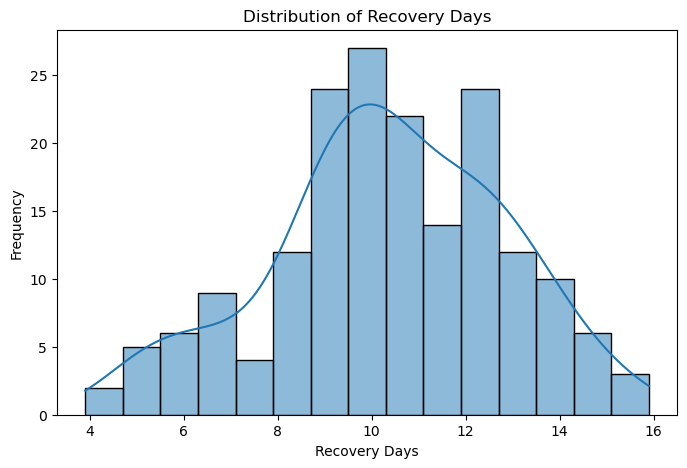

In [11]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Recovery_Days",
    bins=15,
    kde=True
)

plt.title("Distribution of Recovery Days")
plt.xlabel("Recovery Days")
plt.ylabel("Frequency")

plt.show()

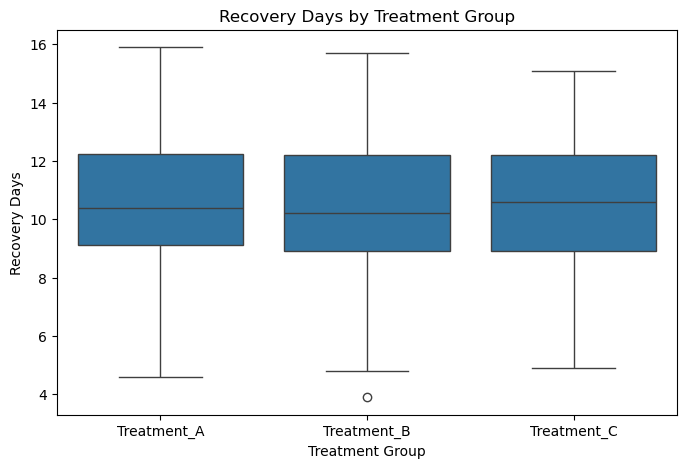

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Treatment",
    y="Recovery_Days"
)

plt.title("Recovery Days by Treatment Group")
plt.xlabel("Treatment Group")
plt.ylabel("Recovery Days")

plt.show()

In [13]:
statistic, p_value = stats.shapiro(
    df["Recovery_Days"]
)

print("Shapiro-Wilk Test")
print("Test Statistic:", statistic)
print("P-value:", p_value)

if p_value > 0.05:
    print("Normality is not rejected.")
else:
    print("Evidence suggests deviation from normality.")

Shapiro-Wilk Test
Test Statistic: 0.9870173451428139
P-value: 0.09620211576530904
Normality is not rejected.


In [14]:
standardized_data = stats.zscore(
    df["Recovery_Days"]
)

statistic, p_value = stats.kstest(
    standardized_data,
    "norm"
)

print("Kolmogorov-Smirnov Test")
print("Test Statistic:", statistic)
print("P-value:", p_value)

Kolmogorov-Smirnov Test
Test Statistic: 0.057118951236055066
P-value: 0.5796781230679587


In [15]:
group_a = df.loc[
    df["Treatment"] == "Treatment_A",
    "Recovery_Days"
]

group_b = df.loc[
    df["Treatment"] == "Treatment_B",
    "Recovery_Days"
]

t_statistic, p_value = stats.ttest_ind(
    group_a,
    group_b,
    equal_var=False
)

print("Independent Two-Sample t-Test")
print("T-statistic:", t_statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("A statistically significant difference was detected.")
else:
    print("Insufficient evidence of a difference in mean recovery times.")

Independent Two-Sample t-Test
T-statistic: 0.3572626908939814
P-value: 0.7215514142378529
Insufficient evidence of a difference in mean recovery times.


In [16]:
u_statistic, p_value = stats.mannwhitneyu(
    group_a,
    group_b,
    alternative="two-sided"
)

print("Mann-Whitney U Test")
print("U-statistic:", u_statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("A statistically significant difference was detected.")
else:
    print("Insufficient evidence of a difference between the distributions.")

Mann-Whitney U Test
U-statistic: 1941.5
P-value: 0.7608278935684393
Insufficient evidence of a difference between the distributions.


In [17]:
group_c = df.loc[
    df["Treatment"] == "Treatment_C",
    "Recovery_Days"
]

f_statistic, p_value = stats.f_oneway(
    group_a,
    group_b,
    group_c
)

print("One-Way ANOVA")
print("F-statistic:", f_statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("At least one group mean differs.")
else:
    print("Insufficient evidence of a difference in group means.")

One-Way ANOVA
F-statistic: 0.09653243788769533
P-value: 0.9080282130869077
Insufficient evidence of a difference in group means.


In [18]:
tukey_results = pairwise_tukeyhsd(
    endog=df["Recovery_Days"],
    groups=df["Treatment"],
    alpha=0.05
)

print(tukey_results)

     Multiple Comparison of Means - Tukey HSD, FWER=0.05     
   group1      group2   meandiff p-adj   lower  upper  reject
-------------------------------------------------------------
Treatment_A Treatment_B  -0.1699 0.9259 -1.2441 0.9044  False
Treatment_A Treatment_C   0.0144 0.9995 -1.0599 1.0886  False
Treatment_B Treatment_C   0.1842 0.9191 -0.9287 1.2971  False
-------------------------------------------------------------


In [19]:
model = ols(
    "Recovery_Days ~ C(Treatment) + C(Gender) + C(Treatment):C(Gender)",
    data=df
).fit()

anova_results = anova_lm(
    model,
    typ=2
)

print("Two-Way ANOVA Results")
print(anova_results)

Two-Way ANOVA Results
                             sum_sq     df         F    PR(>F)
C(Treatment)               1.109355    2.0  0.087956  0.915842
C(Gender)                  6.931177    1.0  1.099083  0.295921
C(Treatment):C(Gender)    14.065399    2.0  1.115181  0.330188
Residual                1097.301127  174.0       NaN       NaN


In [20]:
result = stats.ttest_ind(
    group_a,
    group_b,
    equal_var=False
)

mean_difference = group_a.mean() - group_b.mean()

degrees_of_freedom = result.df

standard_error = np.sqrt(
    group_a.var(ddof=1) / len(group_a)
    + group_b.var(ddof=1) / len(group_b)
)

critical_value = stats.t.ppf(
    0.975,
    degrees_of_freedom
)

lower_limit = mean_difference - critical_value * standard_error
upper_limit = mean_difference + critical_value * standard_error

print("Mean Difference:", mean_difference)

print(
    "95% Confidence Interval:",
    (lower_limit, upper_limit)
)

Mean Difference: 0.16985645933014482
95% Confidence Interval: (np.float64(-0.7719184312505437), np.float64(1.1116313499108332))


# Conclusion

This project demonstrates advanced statistical analysis using Python.

The analysis includes:

1. Exploratory data analysis.
2. Histogram and box plot visualizations.
3. Shapiro-Wilk normality testing.
4. Kolmogorov-Smirnov distribution testing.
5. Independent two-sample t-testing.
6. Mann-Whitney U testing.
7. One-Way ANOVA.
8. Two-Way ANOVA.
9. Tukey HSD post-hoc analysis.
10. Confidence interval estimation.

The statistical results were used to evaluate differences
between treatment groups in the synthetic dataset.

All findings are based on simulated data and are intended
for educational purposes.